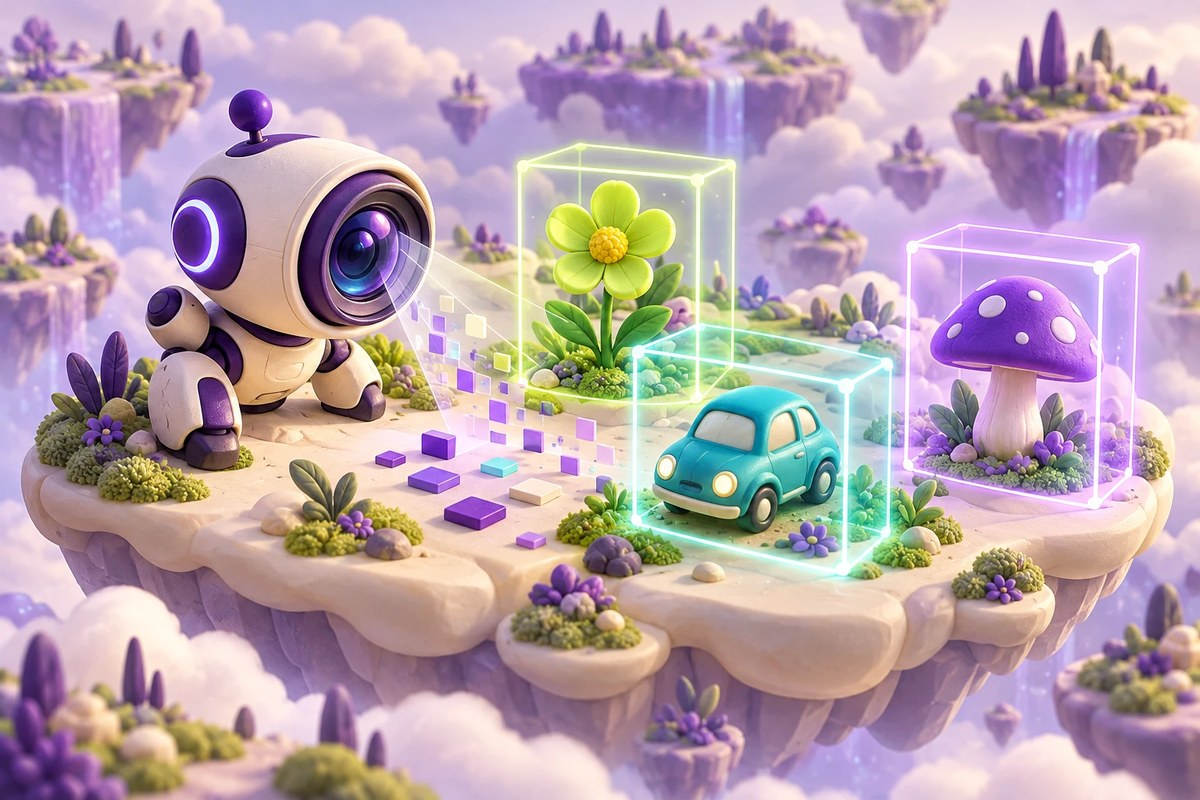

AI PATH · Компьютерное зрение · Урок 005

# Автомобили: классификация из папок с изображениями

Генераторы данных, аугментации и цена большой CNN

**Архивный учебный материал.** Код и сохранённые результаты относятся к исходному ноутбуку. Оформление не означает новый запуск или подтверждение старых метрик. Перед выполнением проверьте зависимости и ограничения.

<a id="ai-005-goal"></a>
## Что вы разберёте

Проверить договорённость между папками классов, формой изображения и архитектурой перед длительным обучением.

### Перед началом

- Папки и пути в Colab
- Пакеты изображений и метки классов
- Основы Conv2D

### Что понадобится

- Colab и Drive и middle_fmr.zip по исходному пути
- После распаковки ожидается каталог /content/cars с подпапками классов
- TensorFlow/Keras, NumPy, Matplotlib и Pillow
- Достаточный объём памяти для исходной сети; GPU может ускорить обучение

## Навигация по уроку

- [Цель и подготовка](#ai-005-goal)
- [Карта урока](#ai-005-map)
- [Подключить библиотеки и архив](#ai-005-section-01)
- [Проверить набор автомобилей](#ai-005-section-02)
- [Разобрать пакет и аугментацию](#ai-005-section-03)
- [Оценить размер сети перед обучением](#ai-005-section-04)
- [Проверьте понимание](#ai-005-practice)
- [Источники и ограничения](#ai-005-provenance)

<a id="ai-005-map"></a>
## Карта урока

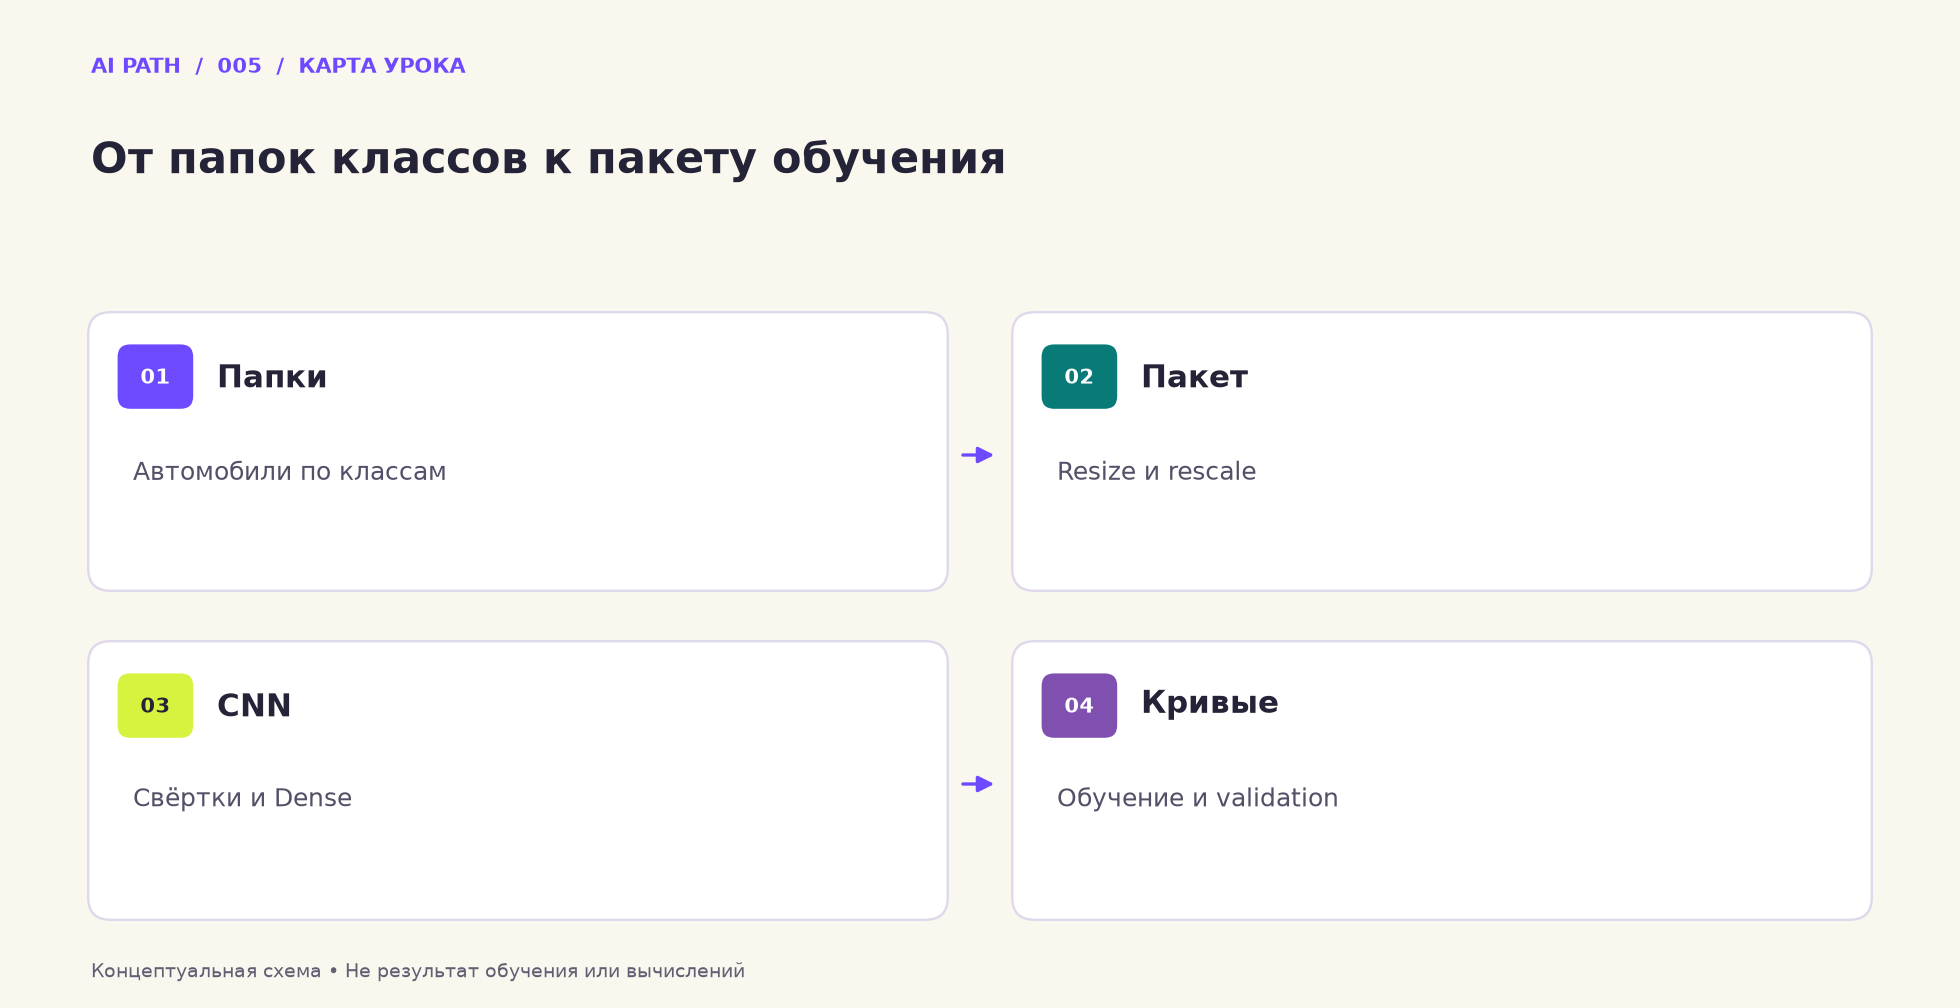

Схема показывает последовательность идей. Она не содержит результатов нового обучения или вычислений.

1. **Папки** — Автомобили по классам
2. **Пакет** — Resize и rescale
3. **CNN** — Свёртки и Dense
4. **Кривые** — Обучение и validation

<a href="https://colab.research.google.com/github/safal207/hello-world/blob/master/%D0%97%D0%B0%D0%B4%D0%B0%D1%87%D0%B0_%D0%BA%D0%BB%D0%B0%D1%81%D1%81%D0%B8%D1%84%D0%B8%D0%BA%D0%B0%D1%86%D0%B8%D1%8F_%D0%B0%D0%B2%D1%82%D0%BE_%D0%BF%D0%BE_%D1%84%D0%BE%D1%82%D0%BE_(3_%D0%BC%D0%B0%D1%80%D0%BA%D0%B8_%D0%B0%D0%B2%D1%82%D0%BE)_%D0%A0%D0%B5%D0%B7%D1%83%D0%BB%D1%8C%D1%82%D0%B0%D1%82_%D1%82%D0%BE%D1%87%D0%BD%D0%BE%D1%81%D1%82%D1%8C_77_%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a id="ai-005-section-01"></a>
## 01 · Подключить библиотеки и архив

Проверьте содержимое архива и структуру папок до создания генератора; имена подпапок определяют метки.

_Далее — исходные ячейки учебного материала._

In [ ]:
from tensorflow.keras.datasets import mnist #Загружаем базу mnist
from tensorflow.keras.datasets import cifar10 #Загружаем базу cifar10
from tensorflow.keras.datasets import cifar100 #Загружаем базу cifar100

from tensorflow.keras.models import Sequential #Сеть прямого распространения
#Базовые слои для счёрточных сетей
from tensorflow.keras.layers import Dense, Conv2D, MaxPooling2D,GlobalMaxPooling2D,AveragePooling2D, Flatten, Dropout, BatchNormalization
from tensorflow.python.keras.preprocessing.image import ImageDataGenerator # работа с изображениями
from tensorflow.keras.optimizers import Adam, Adadelta # оптимизаторы
from tensorflow.keras import utils #Используем дял to_categoricall
from tensorflow.keras.preprocessing import image #Для отрисовки изображений
from google.colab import files #Для загрузки своей картинки
import numpy as np #Библиотека работы с массивами
import matplotlib.pyplot as plt #Для отрисовки графиков
from PIL import Image #Для отрисовки изображений
import random #Для генерации случайных чисел 
import math # Для округления
import os #Для работы с файлами 
# подключем диск
from google.colab import drive

%matplotlib inline

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


<a id="ai-005-section-02"></a>
## 02 · Проверить набор автомобилей

После распаковки сравните число файлов по классам и убедитесь, что целевой каталог не содержит посторонних изображений.

_Далее — исходные ячейки учебного материала._

In [ ]:
!unzip -q "/content/drive/My Drive/Базы/Занятие_3/middle_fmr.zip" -d /content/cars #Указываем путь к базе в Google Drive

<a id="ai-005-section-03"></a>
## 03 · Разобрать пакет и аугментацию

Генератор масштабирует пиксели и применяет случайные преобразования. Отдельно сверьте порядок высоты/ширины: учебный просмотр и генератор используют его по-разному.

_Далее — исходные ячейки учебного материала._

Found 3086 images belonging to 3 classes.
Found 341 images belonging to 3 classes.


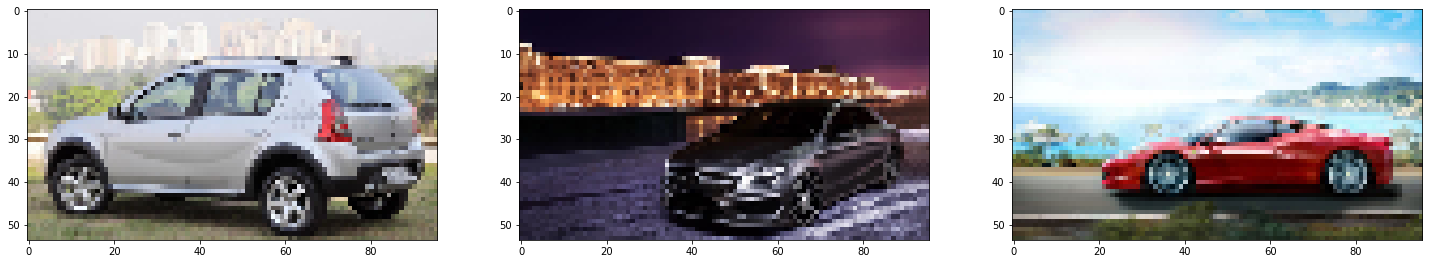

In [ ]:
train_path = '/content/cars' #Папка с папками картинок, рассортированных по категориям
batch_size = 25 #yРазмер выборки
img_width = 96 #Ширина изображения
img_height = 54 #Высота изображения

#Генератор изображений
datagen = ImageDataGenerator(
    rescale=1. / 255, #Значения цвета меняем на дробные показания
    rotation_range=30, #Поворачиваем изображения при генерации выборки
    width_shift_range=0.2, #Двигаем изображения по ширине при генерации выборки
    height_shift_range=0.2, #Двигаем изображения по высоте при генерации выборки
    zoom_range=0.2, #Зумируем изображения при генерации выборки
    horizontal_flip=True, # Включаем отзеркаливание изображений
    fill_mode='nearest', #Заполнение пикселей вне границ ввода
    validation_split=0.1 #Указываем разделение изображений на обучающую и тестовую выборку
)
# обучающая выборка
train_generator = datagen.flow_from_directory(
    train_path, #Путь ко всей выборке выборке
    target_size=(img_width, img_height), #Размер изображений
    batch_size=batch_size, #Размер batch_size
    class_mode='categorical', #Категориальный тип выборки. Разбиение выборки по маркам авто 
    shuffle=True, #Перемешивание выборки
    subset='training' # устанавливаем как набор для обучения
)

# проверочная выборка
validation_generator = datagen.flow_from_directory(
    train_path, #Путь ко всей выборке выборке
    target_size=(img_width, img_height), #Размер изображений
    batch_size=batch_size, #Размер batch_size
    class_mode='categorical', #Категориальный тип выборки. Разбиение выборки по маркам авто 
    shuffle=True, #Перемешивание выборки
    subset='validation' # устанавливаем как валидационный набор
)

#Выводим для примера картинки по каждому классу

fig, axs = plt.subplots(1, 3, figsize=(25, 5)) #Создаем полотно из 3 графиков
for i in range(3): #Проходим по всем классам
  car_path = train_path + '/' + os.listdir(train_path)[i] + '/'#Формируем путь к выборке
  img_path = car_path + random.choice(os.listdir(car_path)) #Выбираем случайное фото для отображения
  axs[i].imshow(image.load_img(img_path, target_size=(img_height, img_width))) #Отображение фотографии

plt.show() #Показываем изображения

# ЦЕЛЬ (3 марки авто) Точность 80% 

---




<a id="ai-005-section-04"></a>
## 04 · Оценить размер сети перед обучением

В исходнике есть слои с 1256, 1512 и 2024 фильтрами и большие Dense. Изучите summary и потребление памяти раньше, чем запускать 45 эпох.

_Далее — исходные ячейки учебного материала._

Epoch 1/45
123/123 [==============================] - 151s 1s/step - loss: 1.0822 - accuracy: 0.3884 - val_loss: 1.0297 - val_accuracy: 0.3569
Epoch 2/45
123/123 [==============================] - 147s 1s/step - loss: 0.9561 - accuracy: 0.5132 - val_loss: 0.9441 - val_accuracy: 0.5015
Epoch 3/45
123/123 [==============================] - 147s 1s/step - loss: 0.9213 - accuracy: 0.5260 - val_loss: 0.9061 - val_accuracy: 0.5169
Epoch 4/45
123/123 [==============================] - 147s 1s/step - loss: 0.9008 - accuracy: 0.5348 - val_loss: 0.9367 - val_accuracy: 0.5200
Epoch 5/45
123/123 [==============================] - 147s 1s/step - loss: 0.8995 - accuracy: 0.5394 - val_loss: 0.9348 - val_accuracy: 0.5477
Epoch 6/45
123/123 [==============================] - 147s 1s/step - loss: 0.8857 - accuracy: 0.5358 - val_loss: 0.8812 - val_accuracy: 0.5200
Epoch 7/45
123/123 [==============================] - 147s 1s/step - loss: 0.8696 - accuracy: 0.5678 - val_loss: 0.8995 - val_accuracy: 0.5415

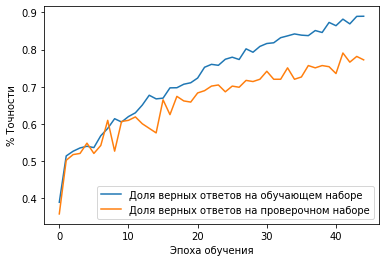

In [ ]:
#Создаем последовательную модель
model = Sequential()
#Первый сверточный слой
model.add(Conv2D(256, (9, 3), padding='same', activation='relu', input_shape=(img_width, img_height, 3)))
#Второй сверточный слой
model.add(Conv2D(1256, (3, 9), padding='same', activation='relu'))
model.add(MaxPooling2D(pool_size=(3, 3)))
#Третий сверточный слой
model.add(Conv2D(256, (9, 3), padding='same', activation='relu'))
#Слой регуляризации Dropout
model.add(Dropout(0.2))
#Четвертый сверточный слой
model.add(Conv2D(256, (3, 9), padding='same', activation='relu'))
model.add(MaxPooling2D(pool_size=(3, 3)))
#Слой регуляризации Dropout
model.add(Dropout(0.2))
#Пятый сверточный слой
model.add(Conv2D(1512, (3, 3), padding='same', activation='relu'))
#Шестой сверточный слой
model.add(Conv2D(2024, (3, 3), padding='same', activation='relu'))
model.add(MaxPooling2D(pool_size=(3, 3)))
#Слой регуляризации Dropout
model.add(Dropout(0.2))
#Слой преобразования двумерных данных в одномерные 
model.add(Flatten())
#Полносвязный слой
model.add(Dense(2048, activation='relu'))
#Полносвязный слой
model.add(Dense(4096, activation='relu'))
#Вызодной полносвязный слой
model.add(Dense(len(train_generator.class_indices), activation='softmax'))

model.compile(loss='categorical_crossentropy', optimizer=Adam(lr=0.0001), metrics=['accuracy'])
history = model.fit_generator(
    train_generator,
    steps_per_epoch = train_generator.samples // batch_size,
    validation_data = validation_generator, 
    validation_steps = validation_generator.samples // batch_size,
    epochs=45,
    verbose=1
)

#Оображаем график точности обучения
#plt.subplot(212)
#plt.title('accuracy')
plt.plot(history.history['accuracy'], 
         label='Доля верных ответов на обучающем наборе')
plt.plot(history.history['val_accuracy'], 
         label='Доля верных ответов на проверочном наборе')
plt.xlabel('Эпоха обучения')
plt.ylabel('% Точности')


plt.legend()
plt.show()

<a id="ai-005-practice"></a>
## Проверьте понимание

1. Сопоставьте class_indices с названиями папок.
2. Проверьте форму реального пакета и ориентацию показанного изображения.
3. Выясните, получает ли validation случайные аугментации, и как это влияет на сравнение эпох.

### Один самостоятельный эксперимент

В отдельной копии уменьшите число фильтров и Dense-нейронов, сохранив те же данные и стабильную validation без случайных преобразований.

**Критерий успеха:** Записаны число параметров, время эпохи и результаты на одинаковой проверке; целевая точность 80% не выдаётся за полученный результат.

<a id="ai-005-provenance"></a>
## Источники и ограничения

[Исходный ноутбук и его авторские материалы](https://github.com/safal207/students/blob/d848e04c8f8d6e3e8e42ce15fbd98c00612e0e17/CV/%D0%97%D0%B0%D0%B4%D0%B0%D1%87%D0%B0_%D0%BA%D0%BB%D0%B0%D1%81%D1%81%D0%B8%D1%84%D0%B8%D0%BA%D0%B0%D1%86%D0%B8%D1%8F_%D0%B0%D0%B2%D1%82%D0%BE_%D0%BF%D0%BE_%D1%84%D0%BE%D1%82%D0%BE_%283_%D0%BC%D0%B0%D1%80%D0%BA%D0%B8_%D0%B0%D0%B2%D1%82%D0%BE%29_%D0%A0%D0%B5%D0%B7%D1%83%D0%BB%D1%8C%D1%82%D0%B0%D1%82_%D1%82%D0%BE%D1%87%D0%BD%D0%BE%D1%81%D1%82%D1%8C_77_%22.ipynb) · репозиторий `safal207/students`.

Исходные подписи, ссылки, авторство, код, изображения и аудио сохранены. Длинные текстовые выводы могут быть сокращены с указанием источника. Архивные результаты не пересчитывались.

### Перед новым запуском

- Архив изображений на Drive не включён и не проверен.
- Исходная архитектура требует существенной памяти; CPU-запуск 45 эпох может быть длительным.
- train и validation создаются одним генератором со случайными аугментациями; независимого test нет.
- Использованы fit_generator, старый Adam(lr) и внутренние импорты Keras; высота и ширина в предпросмотре и генераторе переставлены.

**Иллюстрации:** обложка направления AI PATH; карта урока подготовлена по содержимому исходных ячеек.